In [37]:
## ทำความสะอาดข้อมูล
import pandas as pd
import numpy as np


df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df = df.drop(columns=['customerID'])

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

In [38]:
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

X = df.drop(columns=['Churn'])
y = df['Churn']

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in X.columns if c not in num_cols]

# ตัวช่วยแปลงข้อมูลอัตโนมัติ
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ]
)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Gaussian Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

In [39]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
summary = []

for name, clf in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', clf)])
    recs, f1s, aucs = [], [], []

    for train_idx, test_idx in skf.split(X, y):
        pipe.fit(X.iloc[train_idx], y.iloc[train_idx])
        preds = pipe.predict(X.iloc[test_idx])
        probs = pipe.predict_proba(X.iloc[test_idx])[:, 1]

        recs.append(recall_score(y.iloc[test_idx], preds))
        f1s.append(f1_score(y.iloc[test_idx], preds))
        aucs.append(roc_auc_score(y.iloc[test_idx], probs))

    summary.append({
        'Model': name,
        'Recall (Mean)': f"{np.mean(recs):.3f}",
        'F1-Score (Mean)': f"{np.mean(f1s):.3f}",
        'ROC-AUC (Mean)': f"{np.mean(aucs):.3f}"
    })

print(pd.DataFrame(summary))

                  Model Recall (Mean) F1-Score (Mean) ROC-AUC (Mean)
0   Logistic Regression         0.553           0.602          0.845
1  Gaussian Naive Bayes         0.875           0.580          0.820
2         Random Forest         0.483           0.547          0.822


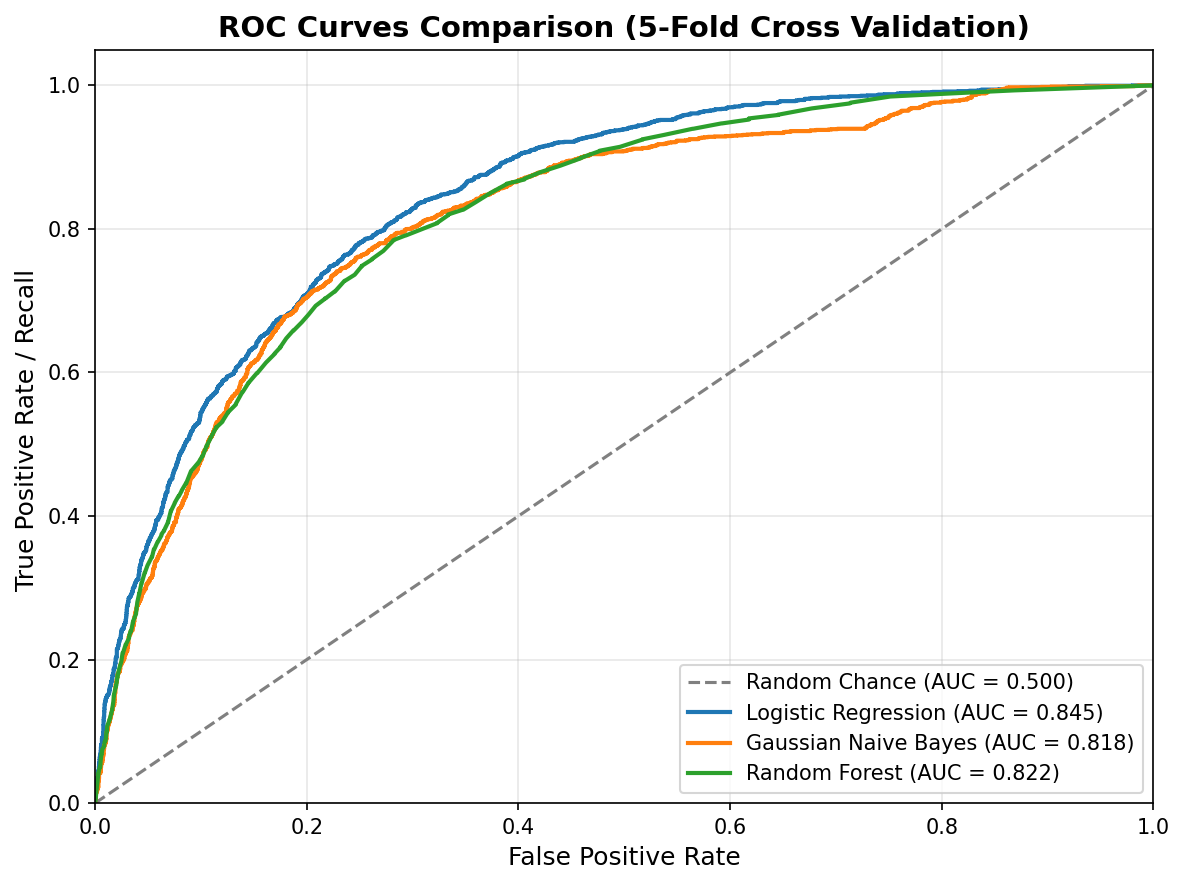

In [45]:
from sklearn.metrics import auc, roc_curve
from sklearn.model_selection import cross_val_predict

plt.figure(figsize=(8, 6), dpi=150)

# วาดเส้นสุ่ม (Baseline)
plt.plot(
    [0, 1],
    [0, 1],
    color='gray',
    linestyle='--',
    label='Random Chance (AUC = 0.500)',
)

# วาดเส้น ROC ของแต่ละโมเดลจากผลการทดสอบ Cross Validation จริง
for name, model in models.items():
  pipe = Pipeline(steps=[('prep', preprocessor), ('clf', model)])

  # คำนวณความน่าจะเป็นเฉพาะบนชุดทดสอบของแต่ละ Fold
  probs = cross_val_predict(
      pipe, X, y, cv=skf, method='predict_proba'
  )[:, 1]

  fpr, tpr, _ = roc_curve(y, probs)
  model_auc = auc(fpr, tpr)
  plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {model_auc:.3f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel(
    'True Positive Rate / Recall ', fontsize=12
)
plt.title(
    'ROC Curves Comparison (5-Fold Cross Validation)',
    fontsize=14,
    fontweight='bold',
)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# บันทึกรูปภาพไปใช้ในสไลด์
plt.savefig('roc_curves_comparison_fixed.png')
plt.show()

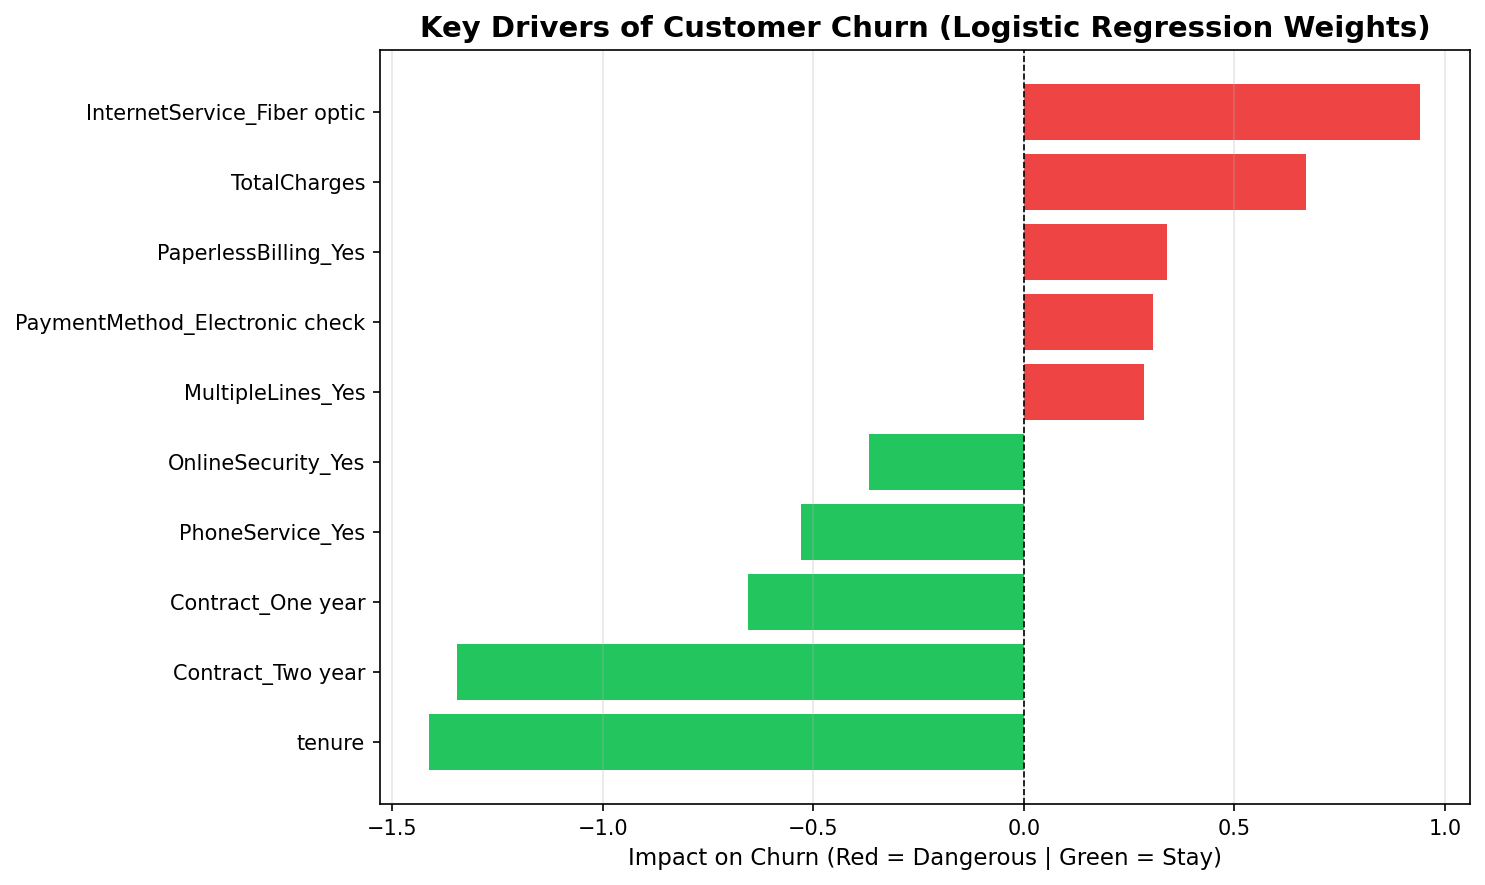

In [46]:
# 1. เทรน Logistic Regression ผ่าน Pipeline
best_model = Pipeline(steps=[('prep', preprocessor), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
best_model.fit(X, y)

# 2. ดึงชื่อคอลัมน์ทั้งหมดหลังผ่านการแปลง One-Hot Encoding
cat_feature_names = best_model.named_steps['prep'].named_transformers_['cat'].get_feature_names_out(cat_cols)
all_feature_names = num_cols + list(cat_feature_names)

# 3. ดึงค่าน้ำหนัก (Coefficients)
coefficients = best_model.named_steps['clf'].coef_[0]

# จัดใส่ DataFrame เพื่อเรียงลำดับ
feat_importance = pd.DataFrame({
    'Feature': all_feature_names,
    'Weight': coefficients
}).sort_values(by='Weight', ascending=False)

# 4. พล็อตกราฟ Top 5 ปัจจัยเสี่ยง และ Top 5 ปัจจัยเหนี่ยวรั้ง
top_churn = feat_importance.head(5)       # ตัวการทำย้ายค่าย
top_loyalty = feat_importance.tail(5)     # ตัวการช่วยให้อยู่ต่อ
top_features = pd.concat([top_churn, top_loyalty]).sort_values(by='Weight')

plt.figure(figsize=(10, 6), dpi=150)
colors = ['#22c55e' if w < 0 else '#ef4444' for w in top_features['Weight']]
plt.barh(top_features['Feature'], top_features['Weight'], color=colors)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Key Drivers of Customer Churn (Logistic Regression Weights)', fontsize=14, fontweight='bold')
plt.xlabel('Impact on Churn (Red = Dangerous | Green = Stay)', fontsize=11)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

# บันทึกรูปภาพ
plt.savefig('feature_importance.png')
plt.show()